## Please refer to the `SGB_contamination_risk_simulation.py` file in the `script` folder first.
You may either download an isochrone with user-defined parameters or use an existing isochrone.

In [18]:
import re
import numpy as np
import matplotlib.pyplot as plt
from belfast.paths import RESULTS_DIR
import pandas as pd

# configuration description
configuration = "SGB_contamination_risk_simulation"

# Root directory
root_dir = RESULTS_DIR / configuration

# Input DataFrame containing SGB parameters
df_path = RESULTS_DIR / configuration / 'test_SGB_parameters.csv'
df = pd.read_csv(df_path)

# Extract P_risk from each folder
risk_dict = {}

for folder in root_dir.iterdir():
    if not folder.is_dir():
        continue

    match = re.match(r'Mock_star_(\d+)_', folder.name)
    if match is None:
        continue

    star_id = int(match.group(1))
    summary_path = folder / 'summary.txt'

    if not summary_path.exists():
        continue

    text = summary_path.read_text(encoding='utf-8')

    risk_match = re.search(
        r'P_risk\s*=\s*([0-9]*\.?[0-9]+)',
        text
    )

    if risk_match is not None:
        risk_dict[star_id] = float(risk_match.group(1))

# Add P_risk according to folder ID (row index)
df['P_risk'] = [risk_dict.get(i, float('nan')) for i in range(len(df))]

# Save the result
output_path = df_path.with_name(f'{df_path.stem}_result{df_path.suffix}')
df.to_csv(output_path, index=False)

print(f'Results saved to: {output_path}')
print(f'Found P_risk for {len(risk_dict)} folders.')

Results saved to: /Users/ziyinggu/Programming/GitHub/BELFAST/results/SGB_contamination_risk_simulation/test_SGB_parameters_result.csv
Found P_risk for 54 folders.


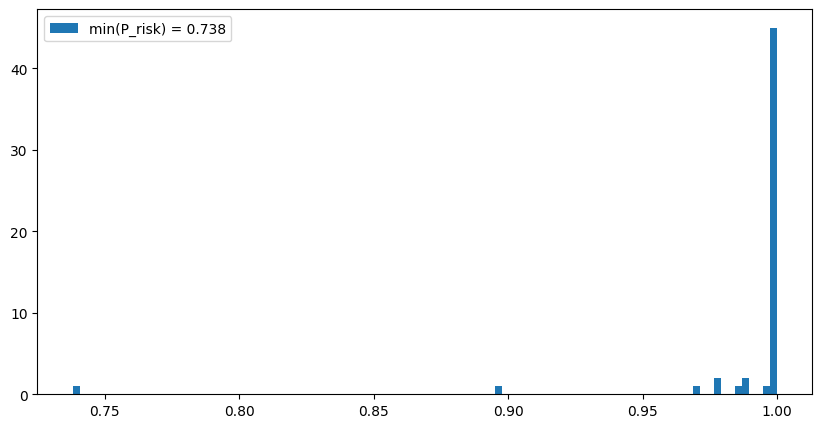

In [19]:
plt.figure(figsize=(10, 5))
plt.hist(df['P_risk'], bins=100, label=f'min(P_risk) = {np.round(np.min(df['P_risk']), 3)}')
plt.legend()
plt.savefig(str(RESULTS_DIR / configuration / 'P_risk.png'), dpi=300)
plt.show()